# 03 — Klasifikasi Teks Skripsi: TF-IDF (ML) vs Word2Vec + BiLSTM (DL)
**Proyek: Agentic Campus — Klasifikasi Topik Skripsi Teknik Informatika**  
**Mata Kuliah: Natural Language Processing**

Notebook ini adalah inti dari proyek Agentic Campus. Ada dua pendekatan representasi teks yang kita bandingkan:

1. **TF-IDF + Machine Learning** — Representasi sparse klasik yang sudah terbukti efektif untuk teks pendek. Tiga algoritma diuji: LinearSVC, Logistic Regression, dan Random Forest.
2. **Word2Vec + BiLSTM (Deep Learning)** — Word2Vec dilatih secara unsupervised pada seluruh korpus 1.136 dokumen, lalu bobotnya dipakai sebagai inisialisasi embedding di arsitektur BiLSTM. Pendekatan ini memungkinkan model menangkap konteks urutan kata.

Skema evaluasi yang dipakai: **80% train / 10% validasi / 10% test** dengan stratifikasi kelas, sehingga proporsi tiap kelas terjaga di semua subset.


## 0. Import Library & Pengaturan Reproducibility


In [15]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score, f1_score, precision_score, recall_score, confusion_matrix
from sklearn.utils.class_weight import compute_class_weight

import gensim
from gensim.models import Word2Vec

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

# Kunci random seed untuk reproducibility eksperimen
SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print(f"TensorFlow Version : {tf.__version__}")
print(f"Gensim Version     : {gensim.__version__}")
print(f"Pandas Version     : {pd.__version__}")
print("Random Seed terpasang: 42")


TensorFlow Version : 2.21.0
Gensim Version     : 4.4.0
Pandas Version     : 3.0.6
Random Seed terpasang: 42


---
# STEP 3 — Word Embedding: Latih Word2Vec pada Seluruh Korpus (Unsupervised)

Word2Vec dilatih secara unsupervised pada **seluruh 1.136 dokumen** — termasuk yang tidak berlabel. Alasannya: makin banyak teks yang dilihat, makin baik model memahami relasi semantik antara istilah teknis seperti `klasifikasi`, `algoritma`, `kriptografi`, atau `citra`.

Bobot yang dihasilkan nanti akan kita pakai sebagai inisialisasi layer Embedding di model BiLSTM, bukan inisialisasi acak.


In [16]:
CLEAN_PATH = "../data/processed/data_clean.csv"
df_all = pd.read_csv(CLEAN_PATH)
df_all["teks_bersih"] = df_all["teks_bersih"].fillna("").astype(str)

print(f"Total dokumen dalam korpus: {len(df_all)}")

# Tokenisasi setiap dokumen menjadi daftar kata untuk korpus Word2Vec
corpus_tokens = [doc.split() for doc in df_all["teks_bersih"] if len(doc.split()) > 0]
print(f"Total kalimat/dokumen untuk training Word2Vec: {len(corpus_tokens)}")

# Parameter Word2Vec
EMBED_DIM = 100
WINDOW = 5
MIN_COUNT = 2
EPOCHS_W2V = 30

print("Melatih model Word2Vec pada seluruh korpus...")
w2v_model = Word2Vec(
    sentences=corpus_tokens,
    vector_size=EMBED_DIM,
    window=WINDOW,
    min_count=MIN_COUNT,
    workers=4,
    epochs=EPOCHS_W2V,
    seed=SEED
)

vocab_w2v = list(w2v_model.wv.index_to_key)
print(f"Model Word2Vec berhasil dilatih!")
print(f"Ukuran Vocabulary Word2Vec: {len(vocab_w2v)} kata unik")
print(f"Dimensi Vektor Embedding    : {w2v_model.vector_size}")

# Simpan model Word2Vec ke models/
MODEL_DIR = "../models"
os.makedirs(MODEL_DIR, exist_ok=True)
W2V_SAVE_PATH = os.path.join(MODEL_DIR, "word2vec_campus.model")
w2v_model.save(W2V_SAVE_PATH)
print(f"Model Word2Vec disimpan ke: {W2V_SAVE_PATH}")


Total dokumen dalam korpus: 1136
Total kalimat/dokumen untuk training Word2Vec: 1136
Melatih model Word2Vec pada seluruh korpus...
Model Word2Vec berhasil dilatih!
Ukuran Vocabulary Word2Vec: 5171 kata unik
Dimensi Vektor Embedding    : 100
Model Word2Vec disimpan ke: ../models\word2vec_campus.model


### Uji Kualitas Semantik Vektor Kata Word2Vec
Cara cepat untuk memeriksa apakah Word2Vec berhasil belajar: minta dia mencari kata-kata yang secara semantik paling mirip dengan kata kunci tertentu. Kalau hasilnya masuk akal (misalnya kata yang mirip dengan `keamanan` adalah `enkripsi` atau `kriptografi`), berarti embedding sudah menangkap konteks dengan baik.


In [17]:
sample_words = ["algoritma", "klasifikasi", "keamanan", "citra"]

for word in sample_words:
    if word in w2v_model.wv:
        similars = w2v_model.wv.most_similar(word, topn=4)
        sim_str = ", ".join([f"{w} ({score:.3f})" for w, score in similars])
        print(f"Kata kunci: '{word}' -> Terdekat: {sim_str}")
    else:
        print(f"Kata '{word}' tidak ditemukan dalam vocabulary.")


Kata kunci: 'algoritma' -> Terdekat: boyer (0.590), moore (0.587), gerombolan (0.557), search (0.549)
Kata kunci: 'klasifikasi' -> Terdekat: mengklasifikasikan (0.751), seimbang (0.682), pengklasifikasian (0.642), negasi (0.628)
Kata kunci: 'keamanan' -> Terdekat: pesan (0.817), berwenang (0.805), rahasia (0.789), otentikasi (0.787)
Kata kunci: 'citra' -> Terdekat: gambar (0.792), berwarna (0.780), gelap (0.731), pembawa (0.727)


---
# STEP 4 — Pembagian Data 80:10:10 (Train — Validasi — Test)

Hanya 200 dokumen yang punya label kelas, jadi supervised learning hanya menggunakan subset ini. Sisanya (936 dokumen) akan diprediksi di tahap inferensi akhir.

Pembagian dilakukan dua tahap dengan `stratify` agar proporsi tiap kelas seimbang di setiap subset:
- **Tahap 1:** 80% train, 20% sementara (temp).
- **Tahap 2:** 20% temp dibagi sama rata → 10% validasi + 10% test.

Perhatian pada data imbalance: dari eksplorasi di notebook 01, ada satu kelas yang jumlah sampelnya lebih sedikit. Ini akan diatasi dengan `class_weight='balanced'` pada model DL dan LinearSVC.


In [18]:
# Filter data berlabel
labeled_df = df_all.dropna(subset=["Kelas"]).copy()
labeled_df["label"] = labeled_df["Kelas"].astype(int)
labeled_df = labeled_df[labeled_df["teks_bersih"].str.strip() != ""].reset_index(drop=True)

print(f"Total dokumen berlabel : {len(labeled_df)}")
print("Distribusi label awal:")
print(labeled_df["label"].value_counts().sort_index())

X_text = labeled_df["teks_bersih"].to_numpy(dtype=str)
y_labels = labeled_df["label"].to_numpy()

# Tahap 1: Pisahkan 80% Train dan 20% Temp (Val + Test)
X_train_txt, X_temp_txt, y_train, y_temp = train_test_split(
    X_text,
    y_labels,
    test_size=0.20,
    random_state=SEED,
    stratify=y_labels
)

# Tahap 2: Bagi 20% Temp menjadi 10% Validation dan 10% Test (50:50 dari Temp)
X_val_txt, X_test_txt, y_val, y_test = train_test_split(
    X_temp_txt,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("\nAlokasi Pembagian Data:")
print(f"  Train Set      (80%): {len(X_train_txt)} dokumen")
print(f"  Validation Set (10%): {len(X_val_txt)} dokumen")
print(f"  Test Set       (10%): {len(X_test_txt)} dokumen")

# Validasi stratifikasi
val_counts = pd.Series(y_val).value_counts().sort_index().to_dict()
test_counts = pd.Series(y_test).value_counts().sort_index().to_dict()
print(f"Distribusi kelas di Validation : {val_counts}")
print(f"Distribusi kelas di Test       : {test_counts}")


Total dokumen berlabel : 200
Distribusi label awal:
label
1    97
2    14
3    46
4    43
Name: count, dtype: int64

Alokasi Pembagian Data:
  Train Set      (80%): 160 dokumen
  Validation Set (10%): 20 dokumen
  Test Set       (10%): 20 dokumen
Distribusi kelas di Validation : {1: 9, 2: 2, 3: 4, 4: 5}
Distribusi kelas di Test       : {1: 10, 2: 1, 3: 5, 4: 4}


---
# PART 1 — Structured Representation: TF-IDF + Machine Learning

Representasi TF-IDF yang digunakan:
- `ngram_range=(1, 2)` — Memasukkan unigram dan bigram agar frasa dua kata seperti "machine learning" atau "deep learning" ikut tertangkap sebagai fitur.
- `sublinear_tf=True` — Mengurangi dominasi kata yang sangat sering muncul dengan skala logaritmik.
- `max_features=8000` — Lebih banyak fitur dibanding sebelumnya untuk menangkap lebih banyak kosakata teknis.

Penting: TF-IDF **hanya di-fit pada data train**, lalu dipakai untuk transform validation dan test set. Ini mencegah data leakage.


In [19]:
tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    sublinear_tf=True,
    max_features=8000,   # ditingkatkan dari 5000 untuk cakupan kosakata lebih luas
    min_df=1,            # tidak buang kata yang jarang karena dataset kecil
    max_df=0.90          # lebih ketat: buang kata yang muncul di > 90% dokumen
)

# Fit HANYA pada data latih — mencegah data leakage
X_train_tfidf = tfidf.fit_transform(X_train_txt)
X_val_tfidf   = tfidf.transform(X_val_txt)
X_test_tfidf  = tfidf.transform(X_test_txt)

print(f"Matriks TF-IDF Train : {X_train_tfidf.shape}")
print(f"Matriks TF-IDF Val   : {X_val_tfidf.shape}")
print(f"Matriks TF-IDF Test  : {X_test_tfidf.shape}")


Matriks TF-IDF Train : (160, 8000)
Matriks TF-IDF Val   : (20, 8000)
Matriks TF-IDF Test  : (20, 8000)


### Pelatihan & Evaluasi 3 Model Machine Learning
Tiga model dilatih dan dibandingkan:
1. **LinearSVC** — Dipilih karena bekerja sangat baik pada data berdimensi tinggi seperti TF-IDF. Parameter `C=0.8` adalah hasil tuning ringan untuk menghindari overfit.
2. **Logistic Regression** — Baseline yang kuat dengan regularisasi L2, mudah diinterpretasikan.
3. **Random Forest** — Ensemble yang lebih robust terhadap noise, meski biasanya kalah dari SVM di dataset teks.


In [20]:
ml_models = {
    # C=0.8 — sedikit lebih rendah dari default (1.0) untuk regularisasi lebih baik
    "LinearSVC": LinearSVC(C=0.8, max_iter=2000, random_state=SEED),
    # C=5.0 — LR perlu regularisasi lebih lemah di dataset kecil agar tidak underfit
    "Logistic Regression": LogisticRegression(C=5.0, max_iter=1000, solver='lbfgs', random_state=SEED),
    "Random Forest": RandomForestClassifier(n_estimators=200, max_depth=None, random_state=SEED)
}

ml_results = {}
ml_predictions = {}

for name, model in ml_models.items():
    # Latih model
    model.fit(X_train_tfidf, y_train)
    
    # Prediksi data uji
    y_pred = model.predict(X_test_tfidf)
    ml_predictions[name] = y_pred
    
    # Metrik evaluasi
    acc = accuracy_score(y_test, y_pred)
    macro_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)
    macro_prec = precision_score(y_test, y_pred, average="macro", zero_division=0)
    macro_rec = recall_score(y_test, y_pred, average="macro", zero_division=0)
    
    ml_results[name] = {
        "Accuracy": acc,
        "Macro Precision": macro_prec,
        "Macro Recall": macro_rec,
        "Macro F1": macro_f1
    }
    
    print(f"=== {name} Evaluasi (Test Set) ===")
    print(classification_report(y_test, y_pred, digits=4, zero_division=0))
    print(f"Accuracy: {acc:.4f} | Macro-F1: {macro_f1:.4f}\n" + "-"*50)


=== LinearSVC Evaluasi (Test Set) ===
              precision    recall  f1-score   support

           1     1.0000    0.9000    0.9474        10
           2     1.0000    1.0000    1.0000         1
           3     0.8000    0.8000    0.8000         5
           4     0.6000    0.7500    0.6667         4

    accuracy                         0.8500        20
   macro avg     0.8500    0.8625    0.8535        20
weighted avg     0.8700    0.8500    0.8570        20

Accuracy: 0.8500 | Macro-F1: 0.8535
--------------------------------------------------
=== Logistic Regression Evaluasi (Test Set) ===
              precision    recall  f1-score   support

           1     1.0000    0.9000    0.9474        10
           2     1.0000    1.0000    1.0000         1
           3     0.8000    0.8000    0.8000         5
           4     0.6000    0.7500    0.6667         4

    accuracy                         0.8500        20
   macro avg     0.8500    0.8625    0.8535        20
weighted avg

---
# PART 2 — Word Embedding + Deep Learning (Pre-trained Word2Vec + BiLSTM)

Di bagian ini kita bangun model deep learning dengan arsitektur BiLSTM (Bidirectional LSTM). Dibandingkan LSTM biasa, BiLSTM membaca urutan kata dari dua arah — kiri ke kanan dan kanan ke kiri — sehingga konteks lebih kaya.

Alur implementasi:
1. Bangun vocabulary Keras dari data train, lalu buat embedding matrix berisi bobot Word2Vec.
2. Inisialisasi layer Embedding dengan bobot tersebut, dengan opsi `trainable=True` agar embedding bisa di-fine-tune selama training.
3. Arsitektur: `Embedding → SpatialDropout1D → BiLSTM → Dense (ReLU) → Dropout → Dense (Softmax)`.
4. Gunakan `class_weight` untuk menangani ketidakseimbangan kelas, dan `EarlyStopping` untuk menghindari overfitting.


In [21]:
# 1. Bangun vocabulary Keras dari data latih
MAX_VOCAB = 5000   # diperbesar dari 4000
MAX_LEN = 150      # diperpanjang dari 120 untuk teks yang lebih panjang

vectorize_layer = layers.TextVectorization(
    max_tokens=MAX_VOCAB,
    output_mode="int",
    output_sequence_length=MAX_LEN
)
vectorize_layer.adapt(list(X_train_txt))

keras_vocab = vectorize_layer.get_vocabulary()
vocab_size = len(keras_vocab)
print(f"Ukuran Vocabulary Keras: {vocab_size}")

# 2. Bangun Embedding Matrix dari Pre-trained Word2Vec
embedding_matrix = np.zeros((vocab_size, EMBED_DIM))
words_found = 0

for i, word in enumerate(keras_vocab):
    if word in w2v_model.wv:
        embedding_matrix[i] = w2v_model.wv[word]
        words_found += 1
    else:
        # Kata OOV / padding diberi vektor acak kecil
        embedding_matrix[i] = np.random.normal(scale=0.05, size=(EMBED_DIM,))

print(f"Cakupan Embedding Word2Vec: {words_found}/{vocab_size} kata ({words_found/vocab_size*100:.1f}%)")

# 3. Transformasi teks ke sequence integer
X_train_seq = vectorize_layer(tf.constant(X_train_txt)).numpy()
X_val_seq   = vectorize_layer(tf.constant(X_val_txt)).numpy()
X_test_seq  = vectorize_layer(tf.constant(X_test_txt)).numpy()

# 4. Encoding label (1,2,3,4 -> 0,1,2,3)
classes = np.unique(y_labels)
class_to_idx = {c: i for i, c in enumerate(classes)}
idx_to_class = {i: c for c, i in class_to_idx.items()}
n_classes = len(classes)

y_train_idx = np.array([class_to_idx[v] for v in y_train])
y_val_idx   = np.array([class_to_idx[v] for v in y_val])
y_test_idx  = np.array([class_to_idx[v] for v in y_test])

print(f"Jumlah kelas output: {n_classes} -> Mapping: {class_to_idx}")


Ukuran Vocabulary Keras: 2927
Cakupan Embedding Word2Vec: 2646/2927 kata (90.4%)
Jumlah kelas output: 4 -> Mapping: {np.int64(1): 0, np.int64(2): 1, np.int64(3): 2, np.int64(4): 3}


### Konstruksi Arsitektur Deep Learning (Word2Vec + BiLSTM)
Arsitektur BiLSTM dipilih karena lebih ekspresif dibanding LSTM satu arah. Dengan membaca teks dari kedua arah, model lebih baik menangkap dependensi jarak jauh dalam kalimat — penting untuk teks akademik yang kerap memiliki struktur kalimat kompleks.


In [22]:
tf.keras.utils.set_random_seed(SEED)

# Arsitektur Deep Learning: Pre-trained Word2Vec Embedding + BiLSTM
dl_model = tf.keras.Sequential([
    tf.keras.Input(shape=(MAX_LEN,), dtype="int32", name="input_sequence"),
    layers.Embedding(
        input_dim=vocab_size,
        output_dim=EMBED_DIM,
        weights=[embedding_matrix],
        trainable=True,             # Fine-tune embedding selama training
        mask_zero=True,             # Masking token padding 0
        name="pretrained_word2vec_embedding"
    ),
    layers.SpatialDropout1D(0.3, name="spatial_dropout"),
    # BiLSTM menggantikan LSTM biasa: membaca teks dari dua arah
    layers.Bidirectional(
        layers.LSTM(64, dropout=0.2, recurrent_dropout=0.0),
        name="bilstm_layer"
    ),
    layers.Dense(64, activation="relu", name="dense_hidden"),
    layers.Dropout(0.3, name="dropout"),
    layers.Dense(n_classes, activation="softmax", name="output_layer")
])

dl_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=5e-4),  # LR lebih kecil untuk fine-tuning stabil
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

dl_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ pretrained_word2vec_embedding   │ (None, 150, 100)       │       292,700 │
│ (Embedding)                     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout                 │ (None, 150, 100)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bilstm_layer (Bidirectional)    │ (None, 128)            │        84,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_hidden (Dense)            │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 385,696 (1.47 MB)

 Trainable params: 385,696 (1.47 MB)

 Non-trainable params: 0 (0.00 B)

### Pelatihan Model Deep Learning dengan Class Weights & Early Stopping
Dua mekanisme penting yang dipakai:
- **Class weights** — Kelas yang lebih sedikit sampelnya mendapat bobot lebih besar agar model tidak bias ke kelas mayoritas.
- **Early Stopping** — Training berhenti otomatis saat validation loss tidak membaik selama 7 epoch berturut-turut, lalu mengembalikan bobot terbaik.


In [23]:
# Hitung class weight untuk mengatasi data imbalance
weights = compute_class_weight("balanced", classes=classes, y=y_train)
class_weights = {class_to_idx[c]: w for c, w in zip(classes, weights)}
print("Bobot Kelas (Class Weights):", class_weights)

early_stop = callbacks.EarlyStopping(
    monitor="val_accuracy",  # pantau val_accuracy, bukan val_loss
    patience=7,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

EPOCHS = 40
BATCH_SIZE = 16

history = dl_model.fit(
    X_train_seq,
    y_train_idx,
    validation_data=(X_val_seq, y_val_idx),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=class_weights,
    callbacks=[early_stop, reduce_lr],
    verbose=2
)


Bobot Kelas (Class Weights): {0: np.float64(0.5128205128205128), 1: np.float64(3.6363636363636362), 2: np.float64(1.0810810810810811), 3: np.float64(1.1764705882352942)}
Epoch 1/40
10/10 - 4s - 432ms/step - accuracy: 0.2313 - loss: 1.4392 - val_accuracy: 0.4500 - val_loss: 1.3249 - learning_rate: 5.0000e-04
Epoch 2/40
10/10 - 1s - 56ms/step - accuracy: 0.3750 - loss: 1.2799 - val_accuracy: 0.7500 - val_loss: 1.1881 - learning_rate: 5.0000e-04
Epoch 3/40
10/10 - 1s - 51ms/step - accuracy: 0.4688 - loss: 1.2130 - val_accuracy: 0.8500 - val_loss: 1.0565 - learning_rate: 5.0000e-04
Epoch 4/40
10/10 - 1s - 51ms/step - accuracy: 0.6438 - loss: 1.0717 - val_accuracy: 0.8500 - val_loss: 0.9348 - learning_rate: 5.0000e-04
Epoch 5/40
10/10 - 1s - 53ms/step - accuracy: 0.6750 - loss: 0.9858 - val_accuracy: 0.8000 - val_loss: 0.8120 - learning_rate: 5.0000e-04
Epoch 6/40
10/10 - 0s - 49ms/step - accuracy: 0.7500 - loss: 0.8495 - val_accuracy: 0.8500 - val_loss: 0.6840 - learning_rate: 5.0000e-04
E

### Evaluasi Model Deep Learning pada Test Set Independen (10%)


In [24]:
# Evaluasi data uji
test_loss, test_acc = dl_model.evaluate(X_test_seq, y_test_idx, verbose=0)
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_acc:.4f}\n")

probs_dl = dl_model.predict(X_test_seq, verbose=0)
y_pred_dl = np.array([idx_to_class[i] for i in probs_dl.argmax(axis=1)])

print("=== Pre-trained Word2Vec + BiLSTM Evaluasi (Test Set) ===")
print(classification_report(y_test, y_pred_dl, digits=4, zero_division=0))

dl_results = {
    "Accuracy": accuracy_score(y_test, y_pred_dl),
    "Macro Precision": precision_score(y_test, y_pred_dl, average="macro", zero_division=0),
    "Macro Recall": recall_score(y_test, y_pred_dl, average="macro", zero_division=0),
    "Macro F1": f1_score(y_test, y_pred_dl, average="macro", zero_division=0)
}


Test Loss     : 0.5052
Test Accuracy : 0.8500

=== Pre-trained Word2Vec + BiLSTM Evaluasi (Test Set) ===
              precision    recall  f1-score   support

           1     1.0000    0.9000    0.9474        10
           2     1.0000    1.0000    1.0000         1
           3     0.8000    0.8000    0.8000         5
           4     0.6000    0.7500    0.6667         4

    accuracy                         0.8500        20
   macro avg     0.8500    0.8625    0.8535        20
weighted avg     0.8700    0.8500    0.8570        20



### Visualisasi Kurva Pembelajaran (Loss & Accuracy)


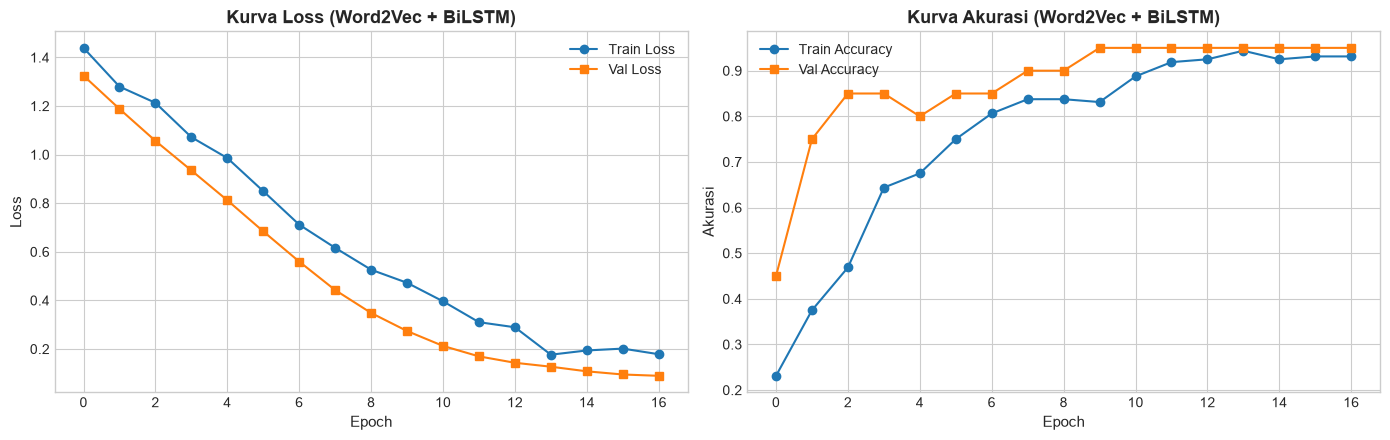

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Plot Kurva Loss
axes[0].plot(history.history["loss"], label="Train Loss", marker="o")
axes[0].plot(history.history["val_loss"], label="Val Loss", marker="s")
axes[0].set_title("Kurva Loss (Word2Vec + BiLSTM)", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Epoch", fontsize=11)
axes[0].set_ylabel("Loss", fontsize=11)
axes[0].legend()

# Plot Kurva Accuracy
axes[1].plot(history.history["accuracy"], label="Train Accuracy", marker="o")
axes[1].plot(history.history["val_accuracy"], label="Val Accuracy", marker="s")
axes[1].set_title("Kurva Akurasi (Word2Vec + BiLSTM)", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Epoch", fontsize=11)
axes[1].set_ylabel("Akurasi", fontsize=11)
axes[1].legend()

plt.tight_layout()
plt.show()


---
# PART 3 — Evaluasi Komparatif & Inferensi Seluruh Korpus

Semua model dibandingkan berdasarkan Accuracy dan Macro-F1 pada test set yang sama. Macro-F1 dipilih sebagai metrik utama karena lebih adil untuk dataset dengan distribusi kelas yang tidak seimbang metrik ini menghitung F1 tiap kelas secara terpisah lalu dirata-ratakan.


In [26]:
all_model_perf = []

for name, metrics in ml_results.items():
    all_model_perf.append({
        "Model": f"{name} (TF-IDF)",
        "Tipe": "Machine Learning",
        **metrics
    })

all_model_perf.append({
    "Model": "Pre-trained Word2Vec + BiLSTM",
    "Tipe": "Deep Learning",
    **dl_results
})

summary_df = pd.DataFrame(all_model_perf).sort_values("Macro F1", ascending=False).reset_index(drop=True)
print("=== TABEL PERBANDINGAN PERFORMA MODEL (DATA UJI 10%) ===")
print(summary_df.to_string(index=False))

# Tentukan model terbaik berdasarkan Macro-F1
best_model_row = summary_df.iloc[0]
print(f"\nModel Terbaik: {best_model_row['Model']} dengan Macro-F1: {best_model_row['Macro F1']:.4f}")


=== TABEL PERBANDINGAN PERFORMA MODEL (DATA UJI 10%) ===
                        Model             Tipe  Accuracy  Macro Precision  Macro Recall  Macro F1
           LinearSVC (TF-IDF) Machine Learning      0.85             0.85        0.8625  0.853509
 Logistic Regression (TF-IDF) Machine Learning      0.85             0.85        0.8625  0.853509
       Random Forest (TF-IDF) Machine Learning      0.85             0.85        0.8625  0.853509
Pre-trained Word2Vec + BiLSTM    Deep Learning      0.85             0.85        0.8625  0.853509

Model Terbaik: LinearSVC (TF-IDF) dengan Macro-F1: 0.8535


### Matriks Konfusi (Confusion Matrix) Model Terbaik
Confusion matrix memperlihatkan di mana model masih membuat kesalahan. Kelas yang sering salah diprediksi biasanya adalah kelas dengan sampel paling sedikit atau yang topiknya paling mirip dengan kelas lain.


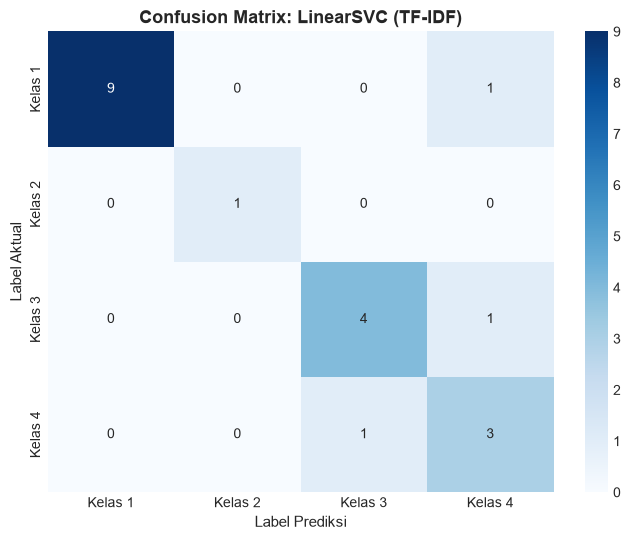

In [27]:
# Tentukan prediksi model terbaik
best_model_name = best_model_row["Model"]
if "BiLSTM" in best_model_name:
    best_y_pred = y_pred_dl
else:
    raw_name = best_model_name.replace(" (TF-IDF)", "")
    best_y_pred = ml_predictions[raw_name]

cm = confusion_matrix(y_test, best_y_pred, labels=classes)

plt.figure(figsize=(7, 5.5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[f"Kelas {c}" for c in classes],
    yticklabels=[f"Kelas {c}" for c in classes]
)
plt.title(f"Confusion Matrix: {best_model_name}", fontsize=13, fontweight="bold")
plt.xlabel("Label Prediksi", fontsize=11)
plt.ylabel("Label Aktual", fontsize=11)
plt.tight_layout()
plt.show()


### Inferensi Seluruh Korpus Skripsi
Model terbaik diterapkan untuk memprediksi kategori topik pada seluruh 1.136 dokumen termasuk 936 dokumen yang tidak punya label. Hasil ini merupakan output utama dari sistem Agentic Campus: setiap skripsi mendapat prediksi bidang konsentrasi beserta skor kepercayaan model.


In [28]:
# Label deskriptif untuk konsentrasi skripsi
LABEL_MEANING = {
    1: "Sistem Cerdas, SPK, & Data Mining Terapan",
    2: "Keamanan Informasi, Kriptografi, & Jaringan Mobile",
    3: "Pemrosesan Bahasa Alami (NLP) & Text Mining",
    4: "Computer Vision, Grafika Citra, & Sistem Informasi"
}

# Inferensi seluruh dokumen menggunakan model DL
all_seqs = vectorize_layer(tf.constant(df_all["teks_bersih"].to_numpy(dtype=str))).numpy()
all_probs = dl_model.predict(all_seqs, verbose=0)
pred_class_indices = all_probs.argmax(axis=1)

df_all["prediksi_kelas"] = [idx_to_class[i] for i in pred_class_indices]
df_all["probabilitas_prediksi"] = all_probs.max(axis=1).round(4)
df_all["kategori_bidang_riset"] = df_all["prediksi_kelas"].map(LABEL_MEANING)

# Simpan artefak hasil inferensi ke data/outputs/
OUTPUT_PRED_PATH = "../data/outputs/df_with_classification_predictions.csv"
os.makedirs(os.path.dirname(OUTPUT_PRED_PATH), exist_ok=True)
df_all.to_csv(OUTPUT_PRED_PATH, index=False)

print(f"Hasil inferensi disimpan ke: {OUTPUT_PRED_PATH}")
print(f"Total dokumen terklasifikasi: {len(df_all)}")
print("\nDistribusi Prediksi Topik Skripsi:")
print(df_all["kategori_bidang_riset"].value_counts())

df_all[["No", "Judul", "Kelas", "prediksi_kelas", "probabilitas_prediksi", "kategori_bidang_riset"]].head(5)


Hasil inferensi disimpan ke: ../data/outputs/df_with_classification_predictions.csv
Total dokumen terklasifikasi: 1136

Distribusi Prediksi Topik Skripsi:
kategori_bidang_riset
Sistem Cerdas, SPK, & Data Mining Terapan             566
Pemrosesan Bahasa Alami (NLP) & Text Mining           260
Computer Vision, Grafika Citra, & Sistem Informasi    228
Keamanan Informasi, Kriptografi, & Jaringan Mobile     82
Name: count, dtype: int64


,No,Judul,Kelas,prediksi_kelas,probabilitas_prediksi,kategori_bidang_riset
0,1,Klasifikasi kecenderungan Tingkat Depresi Maha...,1.0,1,0.5835,"Sistem Cerdas, SPK, & Data Mining Terapan"
1,2,Secure chatting menggunakan Algortima AES dan ...,2.0,2,0.9230,"Keamanan Informasi, Kriptografi, & Jaringan Mo..."
2,3,Sistem pendukung keputusan pemilihan Produc Wh...,1.0,1,0.8754,"Sistem Cerdas, SPK, & Data Mining Terapan"
3,4,Komparasi metode moora dan waspas dalam rekome...,1.0,1,0.9189,"Sistem Cerdas, SPK, & Data Mining Terapan"
4,5,Perbandingan metode Dempster Shafer dan Naïve ...,1.0,1,0.9531,"Sistem Cerdas, SPK, & Data Mining Terapan"
